In [1]:
import pandas as pd

# Читаем только заголовки - Для проверки и предварительного анализа
all_cols = pd.read_csv('../data/flights.csv', nrows=0).columns.tolist()

print(f"Всего колонок в файле: {len(all_cols)}")
print("-" * 30)
for i, col in enumerate(all_cols):
    print(f"{i+1}. {col}")

Всего колонок в файле: 31
------------------------------
1. YEAR
2. MONTH
3. DAY
4. DAY_OF_WEEK
5. AIRLINE
6. FLIGHT_NUMBER
7. TAIL_NUMBER
8. ORIGIN_AIRPORT
9. DESTINATION_AIRPORT
10. SCHEDULED_DEPARTURE
11. DEPARTURE_TIME
12. DEPARTURE_DELAY
13. TAXI_OUT
14. WHEELS_OFF
15. SCHEDULED_TIME
16. ELAPSED_TIME
17. AIR_TIME
18. DISTANCE
19. WHEELS_ON
20. TAXI_IN
21. SCHEDULED_ARRIVAL
22. ARRIVAL_TIME
23. ARRIVAL_DELAY
24. DIVERTED
25. CANCELLED
26. CANCELLATION_REASON
27. AIR_SYSTEM_DELAY
28. SECURITY_DELAY
29. AIRLINE_DELAY
30. LATE_AIRCRAFT_DELAY
31. WEATHER_DELAY


In [2]:
import numpy as np
import pandas as pd

def load_flight_data_final(n_rows=2100000):
    # Только то, что реально доступно ДО вылета
    cols_to_keep = [
        'MONTH', 'DAY', 'DAY_OF_WEEK', 'AIRLINE', 
        'ORIGIN_AIRPORT', 'DESTINATION_AIRPORT',
        'SCHEDULED_DEPARTURE', 'DISTANCE', 'SCHEDULED_TIME', 
        'SCHEDULED_ARRIVAL', 'ARRIVAL_DELAY', 'TAIL_NUMBER'              # ARRIVAL_DELAY только для таргета!
    ]
    
    df = pd.read_csv('../data/flights.csv', usecols=cols_to_keep, nrows=n_rows)
    
    # 1. Таргет - наша целевая, создадим. Задержка более 15 минут это стандарт в авации (и стандарт FAA для США)
    df = df.dropna(subset=['ARRIVAL_DELAY'])
    df['target'] = (df['ARRIVAL_DELAY'] > 15).astype(np.int8)
    
    # 2. Удаляем колонку-"утечку", а то сломает модель
    df = df.drop('ARRIVAL_DELAY', axis=1)
    
    # 3. Базовый Feature Engineering, попробуем добавить правильные признаки для модели
    df['DEP_HOUR'] = (df['SCHEDULED_DEPARTURE'] // 100).astype(np.int8)
    df['ARR_HOUR'] = (df['SCHEDULED_ARRIVAL'] // 100).astype(np.int8)
    df['IS_WEEKEND'] = df['DAY_OF_WEEK'].isin([6, 7]).astype(np.int8)
    
    # 4. Оптимизация типов для категорий
    cat_cols = ['AIRLINE', 'ORIGIN_AIRPORT', 'DESTINATION_AIRPORT']
    for col in cat_cols:
        df[col] = df[col].astype(str).fillna('UNKNOWN')

    # 5. ВАЖНО: Оптимизация числовых типов (сжимаем int64) - так как модель стала "раздуваться"
    # Обоснование: MONTH (1-12) и DAY (1-31) легко влезают в int8 (-128...127)
    # DISTANCE и время в минутах влезают в int16 (-32768...32767)
    df['MONTH'] = df['MONTH'].astype(np.int8)
    df['DAY'] = df['DAY'].astype(np.int8)
    df['DAY_OF_WEEK'] = df['DAY_OF_WEEK'].astype(np.int8)
    
    # Время (HHMM) и Дистанция могут быть больше 127, берем int16
    df['SCHEDULED_DEPARTURE'] = df['SCHEDULED_DEPARTURE'].astype(np.int16)
    df['SCHEDULED_ARRIVAL'] = df['SCHEDULED_ARRIVAL'].astype(np.int16)
    df['DISTANCE'] = df['DISTANCE'].astype(np.int16)
    df['SCHEDULED_TIME'] = df['SCHEDULED_TIME'].fillna(0).astype(np.int16)
        
    return df

df = load_flight_data_final(2100000)
print(f"Новый размер данных: {df.shape}")
print(f'\n*Колонки:\n{df.columns}')
print(f"\n*Объем данных в памяти: {df.memory_usage(deep=True).sum() / 1024**2:.2f} MB")

Новый размер данных: (2044533, 15)

*Колонки:
Index(['MONTH', 'DAY', 'DAY_OF_WEEK', 'AIRLINE', 'TAIL_NUMBER',
       'ORIGIN_AIRPORT', 'DESTINATION_AIRPORT', 'SCHEDULED_DEPARTURE',
       'SCHEDULED_TIME', 'DISTANCE', 'SCHEDULED_ARRIVAL', 'target', 'DEP_HOUR',
       'ARR_HOUR', 'IS_WEEKEND'],
      dtype='object')

*Объем данных в памяти: 516.70 MB


In [3]:
# Проверка дисбаланса классов
target_stats = df['target'].value_counts(normalize=True)
print("Доля классов:")
print(target_stats)

# Визуализация (опционально, для диплома пригодится)
# target_stats.plot(kind='bar', title='Распределение целевой переменной')

Доля классов:
target
0    0.81093
1    0.18907
Name: proportion, dtype: float64


In [4]:
import numpy as np
import pandas as pd
from sklearn.base import BaseEstimator, TransformerMixin

# Используем Feature Engineering для создания новых колонок и выделения зависимостей для модели
class FlightFeatureEngineer(BaseEstimator, TransformerMixin):
    """
    Класс для продвинутого проектирования признаков (Feature Engineering).
    Превращает базовые данные о рейсах в предиктивные факторы задержек.
    """
    def __init__(self):
        # Словари для хранения статистики, накопленной на этапе обучения (fit)
        self.traffic_map = {}         # загрузка (трафик) аэропорта
        self.airline_load_map = {}    # загрузка авиакомпании
        self.airport_rating_map = {}  # средняя задержка аэропорта (Target Encoding)
        self.airline_rating_map = {}  # средняя задержка авиакомпании (Target Encoding)
        self.global_mean = 0          # среднее по всему датасету для заполнения пропусков
        
    def fit(self, X, y=None):
        """
        Изучает закономерности трафика на тренировочных данных.
        Важно: fit делается только на Train, чтобы избежать утечки данных (Data Leakage).
        """
        # 1. Анализ пропускной способности аэропорта:
        # Считаем количество вылетов из каждого аэропорта в конкретный час каждого дня.
        # Обоснование: Перегрузка ВПП и терминалов — главная причина системных задержек.
        self.traffic_map = X.groupby(['ORIGIN_AIRPORT', 'MONTH', 'DAY', 'DEP_HOUR']).size().to_dict()
        
        # 2. Анализ операционной нагрузки авиакомпании:
        # Считаем рейсы конкретного перевозчика в конкретном аэропорту за день.
        # Обоснование: "Эффект домино" — при нехватке резервных бортов или экипажей 
        # задержка одного рейса срывает всё расписание авиакомпании в этом хабе.
        self.airline_load_map = X.groupby(['ORIGIN_AIRPORT', 'AIRLINE', 'MONTH', 'DAY']).size().to_dict()

        # 3. Расчет статистических рейтингов (Target Encoding)
        # Если передан таргет y, вычисляем "проблемность" аэропортов и компаний.
        if y is not None:
            temp_df = X[['ORIGIN_AIRPORT', 'AIRLINE']].copy()
            temp_df['target'] = y
            self.global_mean = y.mean()
            
            # Средний процент задержек для каждого аэропорта и авиакомпании
            self.airport_rating_map = temp_df.groupby('ORIGIN_AIRPORT')['target'].mean().to_dict()
            self.airline_rating_map = temp_df.groupby('AIRLINE')['target'].mean().to_dict()
        
        return self
        
    def transform(self, X):
        """Применяет накопленные знания и создает новые признаки в DataFrame."""
        X_ = X.copy()
        
        # --- БЛОК 1: ЦИКЛИЧЕСКОЕ ВРЕМЯ ---
        # Обоснование: Обычный час (0-23) — линейный, но время циклично (23:59 ближе к 00:01).
        # Превращаем час в координаты на окружности через синус и косинус.
        X_['hour_sin'] = np.sin(2 * np.pi * X_['DEP_HOUR'] / 24)
        X_['hour_cos'] = np.cos(2 * np.pi * X_['DEP_HOUR'] / 24)
        
        # --- БЛОК 2: НАГРУЗКА И ТРАФИК ---
        # Создаем ключи для быстрого извлечения через .map (ускорение в 10+ раз относительно apply)
        t_key = pd.Series(list(zip(X_['ORIGIN_AIRPORT'], X_['MONTH'], X_['DAY'], X_['DEP_HOUR'])))
        a_key = pd.Series(list(zip(X_['ORIGIN_AIRPORT'], X_['AIRLINE'], X_['MONTH'], X_['DAY'])))
        
        # Извлекаем плотность трафика аэропорта (если данных нет, ставим 1 рейс).
        X_['traffic_density'] = t_key.map(self.traffic_map).fillna(1)
        
        # Извлекаем концентрацию рейсов авиакомпании (AIRLINE_FLIGHT_COUNT).
        X_['AIRLINE_FLIGHT_COUNT'] = a_key.map(self.airline_load_map).fillna(1)
        
        # НОВОЕ: Внедряем числовые рейтинги "проблемности" (помогают ансамблю сопоставлять категории)
        X_['airport_rating'] = X_['ORIGIN_AIRPORT'].map(self.airport_rating_map).fillna(self.global_mean)
        X_['airline_rating'] = X_['AIRLINE'].map(self.airline_rating_map).fillna(self.global_mean)
        
        # --- БЛОК 3: ЛОГИСТИКА И ГЕОГРАФИЯ ---
        # Создаем уникальный идентификатор маршрута (Направление).
        # Обоснование: Определенные коридоры (например, в Нью-Йорк) перегружены чаще других.
        X_['ROUTE'] = X_['ORIGIN_AIRPORT'].astype(str) + "_" + X_['DESTINATION_AIRPORT'].astype(str)
        
        # Рассчитываем плановую скорость полета (мили в минуту).
        # Обоснование: Чем выше плановая скорость, тем меньше "запас" времени у пилота 
        # на компенсацию предвылетной задержки в воздухе.
        X_['plan_speed'] = X_['DISTANCE'] / (X_['SCHEDULED_TIME'] + 1e-5)
        
        # Выделяем ночные рейсы (00:00 - 05:59).
        # Обоснование: Ночью трафик ниже, но задержки могут быть вызваны длительным тех. обслуживанием.
        X_['IS_NIGHT'] = ((X_['DEP_HOUR'] >= 0) & (X_['DEP_HOUR'] <= 5)).astype(int)

        # Удаляем лишние столбцы, чтобы не перегружать модель
        if 'TAIL_NUMBER' in X_.columns:
            X_ = X_.drop(columns=['TAIL_NUMBER'])
        
        # Специально для LightGBM внутри ансамбля: 
        # Приводим категориальные столбцы к типу 'category'
        cat_cols = ['MONTH', 'DAY', 'DAY_OF_WEEK', 'AIRLINE', 
                    'ORIGIN_AIRPORT', 'DESTINATION_AIRPORT', 'ROUTE']
        
        for col in cat_cols:
            if col in X_.columns:
                X_[col] = X_[col].astype('category')

        # --- ОПТИМИЗАЦИЯ ПАМЯТИ ---
        # float32 достаточно для точности координат sin/cos и рейтингов
        float_cols = X_.select_dtypes(include=['float64']).columns
        X_[float_cols] = X_[float_cols].astype('float32')
        
        # int32 надежно держит любые счетчики трафика, не рискуя переполнением
        int_cols = X_.select_dtypes(include=['int64']).columns
        X_[int_cols] = X_[int_cols].astype('int32')
        
        # Для бинарных признаков (0/1) можно использовать uint8 - это самый минимум
        bool_cols = ['IS_WEEKEND', 'IS_NIGHT'] # и другие 0/1 признаки
        for col in bool_cols:
            if col in X_.columns:
                X_[col] = X_[col].astype('uint8')
        
        return X_

In [5]:
# Базовый набор (сырье для трансформера)
base_features = [
    'MONTH', 'DAY', 'DAY_OF_WEEK', 'AIRLINE', 
    'ORIGIN_AIRPORT', 'DESTINATION_AIRPORT',
    'SCHEDULED_DEPARTURE', 'DISTANCE', 'SCHEDULED_TIME', 
    'SCHEDULED_ARRIVAL', 'DEP_HOUR', 'ARR_HOUR', 'IS_WEEKEND'
]

X = df[base_features]
y = df['target']

# Разделяем на Train и Test
from sklearn.model_selection import train_test_split
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)

print(f"Готово! Обучающая выборка: {X_train.shape}")

Готово! Обучающая выборка: (1635626, 13)


In [6]:
print('*Так как CatBoost очень капризен к типам, проверим:\n\n', X_train.dtypes)
print('-'*50)
print(df[['ORIGIN_AIRPORT', 'DESTINATION_AIRPORT', 'AIRLINE']].dtypes)

*Так как CatBoost очень капризен к типам, проверим:

 MONTH                    int8
DAY                      int8
DAY_OF_WEEK              int8
AIRLINE                object
ORIGIN_AIRPORT         object
DESTINATION_AIRPORT    object
SCHEDULED_DEPARTURE     int16
DISTANCE                int16
SCHEDULED_TIME          int16
SCHEDULED_ARRIVAL       int16
DEP_HOUR                 int8
ARR_HOUR                 int8
IS_WEEKEND               int8
dtype: object
--------------------------------------------------
ORIGIN_AIRPORT         object
DESTINATION_AIRPORT    object
AIRLINE                object
dtype: object


In [7]:
# Создаем экземпляр нашего инженера признаков
fe = FlightFeatureEngineer()

# "Обучаем" его на тренировочных данных и сразу трансформируем их
X_train_transformed = fe.fit_transform(X_train)

# Вот ТЕПЕРЬ смотрим на состав колонок
print("Количество колонок ПОСЛЕ Feature Engineering:", X_train_transformed.shape[1])
print("-" * 30)
print(X_train_transformed.dtypes)

# Посмотрим на первые 3 строки новых колонок
print("-" * 30)
print(X_train_transformed[['hour_sin', 'traffic_density', 'AIRLINE_FLIGHT_COUNT', 'ROUTE']].head(3))

Количество колонок ПОСЛЕ Feature Engineering: 22
------------------------------
MONTH                   category
DAY                     category
DAY_OF_WEEK             category
AIRLINE                 category
ORIGIN_AIRPORT          category
DESTINATION_AIRPORT     category
SCHEDULED_DEPARTURE        int16
DISTANCE                   int16
SCHEDULED_TIME             int16
SCHEDULED_ARRIVAL          int16
DEP_HOUR                    int8
ARR_HOUR                    int8
IS_WEEKEND                 uint8
hour_sin                 float32
hour_cos                 float32
traffic_density          float32
AIRLINE_FLIGHT_COUNT     float32
airport_rating           float32
airline_rating           float32
ROUTE                   category
plan_speed               float32
IS_NIGHT                   uint8
dtype: object
------------------------------
             hour_sin  traffic_density  AIRLINE_FLIGHT_COUNT    ROUTE
1831324 -5.000000e-01              NaN                   NaN  ORD_ABE
659397   

In [8]:
# теперь сборка пайплайна и обучение моделей Cat Boost (CatBoostClassifier) + LightGBM (LGBMClassifier)
import time
import numpy as np
from sklearn.ensemble import VotingClassifier
from lightgbm import LGBMClassifier
from catboost import CatBoostClassifier
from sklearn.pipeline import Pipeline
import joblib

# from sklearn import set_config                # для поддержки metada в VotingClassifier - случайно обнаружилось. Иначе вылезает ValueError
##  Включаем поддержку metadata routing
# set_config(enable_metadata_routing=True)

print("\n* Инициализация процессов...\n")
print("Подготовка Ансмбля из  Cat Boost и LightGBM...")
print("Подготовка Пайплайна...")
print('-' * 50)

# 1. Список категориальных признаков для CatBoost
# Указываем признаки, которые являются текстовыми или логическими категориями.
# CatBoost применит к ним встроенный алгоритм кодирования (Ordered TS).
cat_features = [
    'MONTH', 'DAY', 'DAY_OF_WEEK', 'AIRLINE', 
    'ORIGIN_AIRPORT', 'DESTINATION_AIRPORT', 'ROUTE', 
    'IS_WEEKEND', 'IS_NIGHT'
]

# 1.2. Сначала CatBoostClassifier
clf = CatBoostClassifier(
        iterations=2500,          # Количество итераций (деревьев). На GPU можно ставить много.
        learning_rate=0.03,       # Скорость обучения. Чем меньше, тем точнее модель находит закономерности.
        depth=7,                  # Глубина деревьев. 8 — "золотая середина" для табличных данных.
        l2_leaf_reg=12,            # Регуляризация. Предотвращает переобучение на шумах.
        
        # БАЛАНСИРОВКА: В данных 18.9% задержек. Вес 4.28 (81.0/18.9) заставляет модель 
        # фокусироваться на задержках сильнее, чтобы поднять Recall. 
        scale_pos_weight=4.2,     
        
        # АППАРАТНОЕ УСКОРЕНИЕ: Использование видеокарты для сокращения времени обучения.
        task_type="GPU",          
        devices='0', 

        # Определяет стратегию отбора объектов для деревьев
        bootstrap_type='Bernoulli',
        subsample=0.8,
        # Политика роста деревьев - SymmetricTree — по умолчанию; Lossguide — для больших данных.
        grow_policy='SymmetricTree',
        
        # МОНИТОРИНГ: AUC — основная метрика. Recall и Precision выводятся для контроля 
        # способности модели находить реальные опоздания в процессе обучения.
        eval_metric='AUC',
#        custom_metric=['Recall', 'Precision'],                 # Ансамбль VotingClassifier "лёг" из-за этого
        
        random_seed=42,           # Фиксация случайности для воспроизводимости результатов.
        
        # Увеличивает разнообразие деревьев, снижает переобучение (меньше - увереннее, больше - модель сомневается)
        random_strength=2,
        early_stopping_rounds=100, # Если в течение 100 итераций AUC не растет — 
                                   # стопаем обучение. Это спасет от переобучения
        
        verbose=200,               # Печатать лог каждые 200 деревьев.
        cat_features=cat_features  # Указание модели на категориальные столбцы.
    )

## Привести только нужные столбцы к category dtype - только для LightGBM
# X_train[cat_features] = X_train[cat_features].astype('category')
# X_test[cat_features] = X_test[cat_features].astype('category')


# 1.3. А теперь - другая "лесная" модель градиентного бустинга, LGBMClassifier
lgbm = LGBMClassifier(
    n_estimators=1500,           # Количество деревьев
    max_depth=7,                 # Глубина деревьев
    learning_rate=0.03,          # Скорость обучения (золотая середина наверное выбрана)
    subsample=0.8,               # Доля объектов
    random_state=42,             # Всё по классике
    colsample_bytree=0.8,        # Доля признаков, используемых для построения каждого дерева, ускоряет обучение и снижает переобучение
    reg_lambda=6,                # Аналог l2_leaf_reg в CatBoost (L2-регуляризация). Чем выше значение, тем сильнее регуляризация
    scale_pos_weight=4.3,        # Тут я решил выставить отношение дисбаланса как есть
    n_jobs=-1,                   # Позволяет использовать все ядра процессора
    objective='binary',          # функция потерь = Logloss
    metric=['auc','binary_logloss'],     # метрика качества = ROC-AUC и binary_logloss
#    early_stopping_rounds=100,
    verbose=1,
    histogram_pool_size=4096,    # Ограничиваем кэш гистограмм (4ГБ)
    max_bin=255,                 # Стандарт, не даем раздуваться
)

# 1.4. Теперь сборка ансамбля моделей VotingClassifier:
ensemble = VotingClassifier(
    estimators=[('clf', clf), ('lgbm', lgbm)],
    voting='soft',              # Усредняет вероятности классов, учитывает уверенность моделей
    n_jobs=1                    # К сожалению, приходится ставить этот параметр. Никаких распараллеливаний и одновременного обучения моделей
)

# 2. Сборка Pipeline (единый конвейер обработки)
# Это гарантирует, что Feature Engineering применится и к Train, и к Test без ошибок.
model_pipeline = Pipeline([
    # Первый шаг: Наш кастомный класс для создания 6 новых типов признаков
    ('feature_eng', FlightFeatureEngineer()), 
    
    # Второй шаг: Классификатор с настройками под GPU и Recall
    ('ensemble', ensemble)
])

# 3. ИСПОЛНЕНИЕ: ОБУЧЕНИЕ И ЗАМЕР ВРЕМЕНИ
print("\n🛫 Запуск обучения модели на GPU и на CPU с расширенным мониторингом...")

start_time = time.time()                # Засекаем время старта (включает трансформацию данных)

model_pipeline.fit(X_train, y_train)    # ОБУЧЕНИЕ МОДЕЛИ

end_time = time.time()                  # Фиксируем время завершения

# Расчет затраченного времени
training_duration = end_time - start_time
minutes = int(training_duration // 60)
seconds = int(training_duration % 60)

# 1. Сохранение всего пайплайна (Feature Engineering + ансамбль)
# Это основной артефакт: бизнес может загрузить один файл и сразу делать предсказания
joblib.dump(model_pipeline, "../models/model_pipeline_cat_lgbm.pkl", compress=3)

# 2. Сохранение CatBoost отдельно
# CatBoost находится внутри ансамбля (первый элемент в estimators_)
cat_model = model_pipeline.named_steps['ensemble'].estimators_[0]

# # обрезаем модель до лучшей итерации, чтобы убрать лишние деревья
# if hasattr(cat_model, "best_iteration_") and cat_model.best_iteration_ is not None:
#     cat_model.shrink(cat_model.best_iteration_)

# сохраняем в формате .cbm (CatBoost native format)
cat_model.save_model("../models/catboost_model_ens.cbm", format="cbm")

# 3. Сохранение LightGBM отдельно
# LightGBM находится внутри ансамбля (второй элемент в estimators_)
lgbm_model = model_pipeline.named_steps['ensemble'].estimators_[1]

# сохраняем в формате .txt (LightGBM native format)
lgbm_model.booster_.save_model("../models/lightgbm_model_ens.txt")

print("-" * 50)
print("🛬 Модель успешно обучена на 2 млн+ строк!")
print(f"⏱ Суммарное время (FE + Обучение): {minutes} мин. {seconds} сек.")
print("-" * 50)
print("✅ Все модели сохранены:")
print(" - Пайплайн: ../models/model_pipeline.pkl")
print(" - CatBoost: ../models/catboost_model.cbm")
print(" - LightGBM: ../models/lightgbm_model.txt")
print("-" * 50)


* Инициализация процессов...

Подготовка Ансмбля из  Cat Boost и LightGBM...
Подготовка Пайплайна...
--------------------------------------------------

🛫 Запуск обучения модели на GPU и на CPU с расширенным мониторингом...


Default metric period is 5 because AUC is/are not implemented for GPU


0:	total: 683ms	remaining: 28m 27s
200:	total: 39.7s	remaining: 7m 34s
400:	total: 1m 18s	remaining: 6m 49s
600:	total: 1m 59s	remaining: 6m 18s
800:	total: 2m 37s	remaining: 5m 33s
1000:	total: 3m 21s	remaining: 5m 1s
1200:	total: 4m 3s	remaining: 4m 23s
1400:	total: 4m 41s	remaining: 3m 40s
1600:	total: 5m 24s	remaining: 3m 2s
1800:	total: 6m 6s	remaining: 2m 22s
2000:	total: 6m 46s	remaining: 1m 41s
2200:	total: 7m 31s	remaining: 1m 1s
2400:	total: 8m 14s	remaining: 20.4s
2499:	total: 8m 34s	remaining: 0us
[LightGBM] [Warning] Categorical features with more bins than the configured maximum bin number found.
[LightGBM] [Warning] For categorical features, max_bin and max_bin_by_feature may be ignored with a large number of categories.
[LightGBM] [Info] Number of positive: 309248, number of negative: 1326378
[LightGBM] [Info] Auto-choosing col-wise multi-threading, the overhead of testing was 0.185837 seconds.
You can set `force_col_wise=true` to remove the overhead.
[LightGBM] [Info] 


ОТЧЕТ ПО МОДЕЛИ ПРОГНОЗИРОВАНИЯ ЗАДЕРЖЕК
--------------------------------------------------
ВРЕМЯ ОБУЧЕНИЯ: 12 мин. 37 сек.
ROC-AUC SCORE: 0.7765
--------------------------------------------------
МЕТРИКИ КЛАССИФИКАЦИИ:
              precision    recall  f1-score   support

           0       0.90      0.75      0.82    331595
           1       0.38      0.66      0.48     77312

    accuracy                           0.74    408907
   macro avg       0.64      0.71      0.65    408907
weighted avg       0.81      0.74      0.76    408907


✅ Отчет сохранен в файл '../notebooks/model_results.txt'


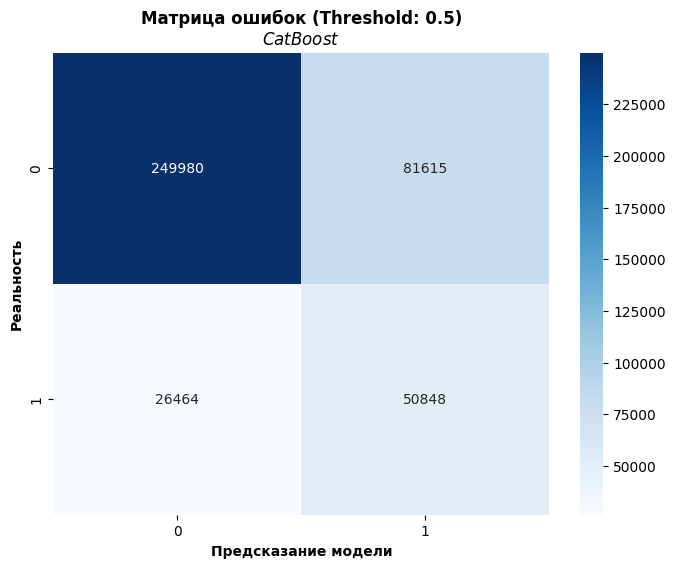

In [9]:
from sklearn.metrics import classification_report, roc_auc_score, confusion_matrix
import matplotlib.pyplot as plt
import seaborn as sns

# 1. Получаем вероятности (вместо жестких классов 0/1)
# Это нужно, чтобы мы могли управлять порогом чувствительности
y_probs = model_pipeline.predict_proba(X_test)[:, 1]

# 2. Устанавливаем порог. 
# Так как мы использовали scale_pos_weight, модель уже смещена.
# Начнем со стандартного 0.5. Если Recall будет ниже 0.80, его можно будет уменьшить.
threshold = 0.5
y_pred = (y_probs >= threshold).astype(int)

# 3. Считаем метрики
report = classification_report(y_test, y_pred)
auc_val = roc_auc_score(y_test, y_probs)

# Формируем итоговый текст
results_text = f"""
ОТЧЕТ ПО МОДЕЛИ ПРОГНОЗИРОВАНИЯ ЗАДЕРЖЕК
--------------------------------------------------
ВРЕМЯ ОБУЧЕНИЯ: {minutes} мин. {seconds} сек.
ROC-AUC SCORE: {auc_val:.4f}
--------------------------------------------------
МЕТРИКИ КЛАССИФИКАЦИИ:
{report}
"""

# Печатаем в консоль
print(results_text)

# Сохраняем в файл .txt
with open("../notebooks/model_results.txt", "w", encoding="utf-8") as f:
    f.write(results_text)

print("✅ Отчет сохранен в файл '../notebooks/model_results.txt'")

# 4. Визуализация матрицы ошибок (Confusion Matrix)
# Это наглядно покажет, сколько задержек мы поймали, а сколько - пропустили
cm = confusion_matrix(y_test, y_pred)
plt.figure(figsize=(8, 6))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues')
plt.title(f'Матрица ошибок (Threshold: {threshold})\n$CatBoost$', weight='bold')
plt.ylabel('Реальность', weight='bold')
plt.xlabel('Предсказание модели', weight='bold')
plt.savefig('../notebooks/Матрица ошибок.jpg', dpi=300)

plt.show()
plt.close()

C:\Users\user\AppData\Local\Temp\ipykernel_48668\469245637.py:19: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x='importance', y='feature', data=fi_df, palette='viridis')


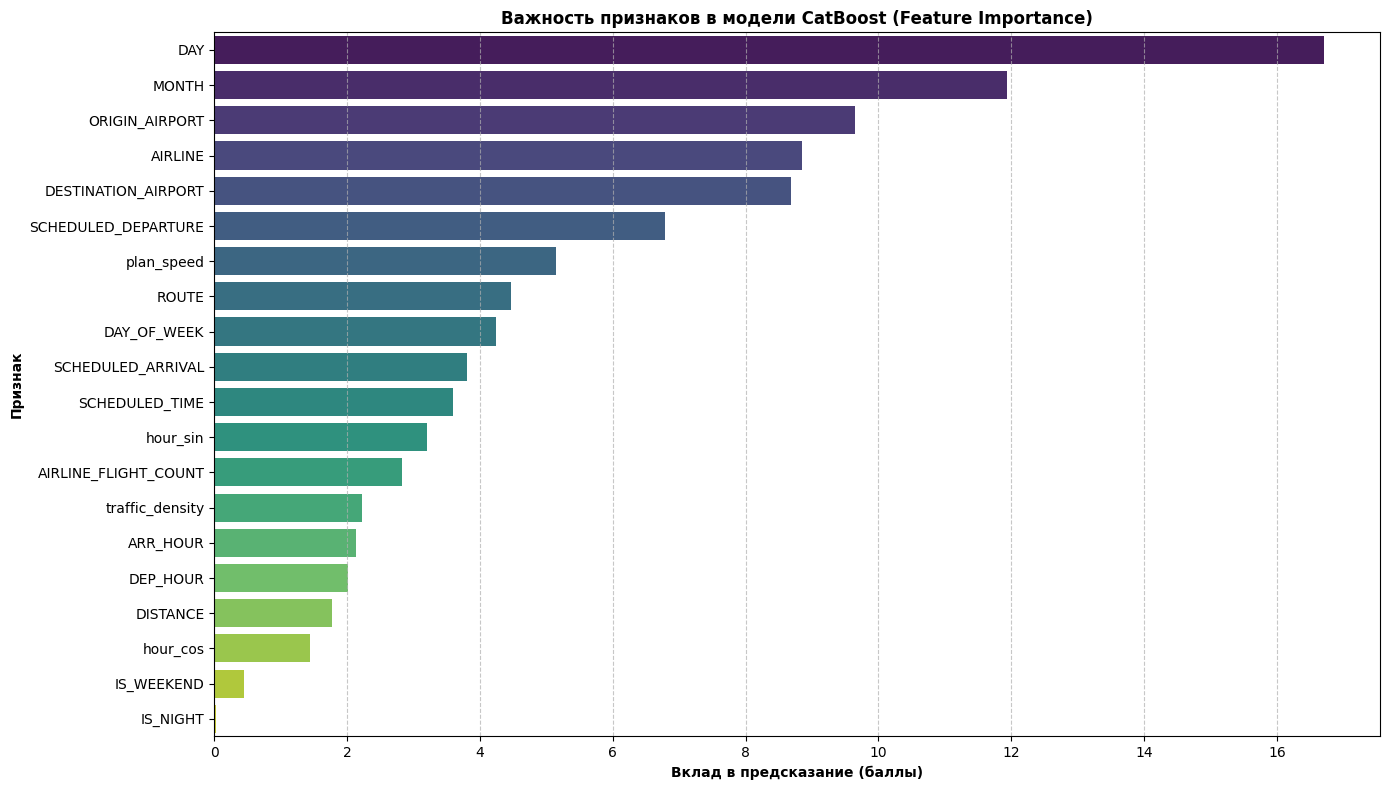

*Выведем Важность признаков (Feature Importance)

                  feature  importance
1                    DAY   16.714104
0                  MONTH   11.940279
4         ORIGIN_AIRPORT    9.651545
3                AIRLINE    8.843162
5    DESTINATION_AIRPORT    8.681130
6    SCHEDULED_DEPARTURE    6.792029
18            plan_speed    5.141562
17                 ROUTE    4.472224
2            DAY_OF_WEEK    4.236983
9      SCHEDULED_ARRIVAL    3.809112
8         SCHEDULED_TIME    3.601622
13              hour_sin    3.200281
16  AIRLINE_FLIGHT_COUNT    2.833665
15       traffic_density    2.230000
11              ARR_HOUR    2.132905
10              DEP_HOUR    2.012705
7               DISTANCE    1.780256
14              hour_cos    1.446643
12            IS_WEEKEND    0.455348
19              IS_NIGHT    0.024446


In [38]:
# Попытка разобраться с важностью признаков - этот анализ покажет, насколько правильным было выбор Feature Engineering
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# 1. Извлекаем важность признаков из модели внутри пайплайна
# Так как у нас Pipeline, мы обращаемся к шагу 'clf'
feature_importance = model_pipeline.named_steps['clf'].get_feature_importance()
feature_names = model_pipeline.named_steps['feature_eng'].transform(X_train.head(1)).columns

# 2. Создаем DataFrame для удобства визуализации
fi_df = pd.DataFrame({
    'feature': feature_names,
    'importance': feature_importance
}).sort_values(by='importance', ascending=False)

# 3. Визуализация
plt.figure(figsize=(14, 8))
sns.barplot(x='importance', y='feature', data=fi_df, palette='viridis')
plt.title('Важность признаков в модели CatBoost (Feature Importance)', weight='bold')
plt.xlabel('Вклад в предсказание (баллы)', weight='bold')
plt.ylabel('Признак', weight='bold')
plt.grid(True, axis='x', linestyle='--', alpha=0.7)
plt.tight_layout()
plt.savefig('notebooks/CatBoost Feature Importance.jpg', dpi=300)

plt.show()
plt.close()

print('*Выведем Важность признаков (Feature Importance)\n\n', fi_df)



In [42]:
# в поиске "идеального" Recall мы пожертвуем Precision и попытаемся узнать нужный нам порог.

import numpy as np
from sklearn.metrics import recall_score, precision_score

# Попробуем разные пороги
thresholds = [0.2, 0.25, 0.3, 0.35, 0.4, 0.45, 0.5]

# 1. Создаем "шапку" таблицы в строковой переменной
report_recall085 = f"{'Threshold':<12} | {'Recall':<10} | {'Precision':<10}\n"
report_recall085 += "-" * 38 + "\n"

# 2. Заполняем таблицу данными в цикле
for t in thresholds:
    y_pred_t = (y_probs >= t).astype(int)
    r = recall_score(y_test, y_pred_t)
    p = precision_score(y_test, y_pred_t)
    
    # Добавляем строку в общую переменную
    row = f"{t:<12} | {r:<10.4f} | {p:<10.4f}\n"
    report_recall085 += row

# 3. Выводим результат в консоль (чтобы видеть процесс)
print(report_recall085)

# 4. Формируем итоговый текст для файла
results_text_recall085 = f"""
ОТЧЕТ ПО УЛУЧШЕНИЮ RECALL ~ 85% (Задержки)
--------------------------------------------------
Данные получены путем перебора порогов классификации.
Целевой Recall (0.8435) достигается при пороге 0.35.
--------------------------------------------------
Таблица метрик:
{report_recall085}
"""

# 5. Сохраняем в файл .txt
with open("notebooks/recall085_results.txt", "w", encoding="utf-8") as f:
    f.write(results_text_recall085)
print("✅ Отчет успешно сохранен в файл 'recall085_results.txt'")

Threshold    | Recall     | Precision 
--------------------------------------
0.2          | 0.9634     | 0.2568    
0.25         | 0.9323     | 0.2808    
0.3          | 0.8910     | 0.3079    
0.35         | 0.8435     | 0.3377    
0.4          | 0.7925     | 0.3704    
0.45         | 0.7361     | 0.4046    
0.5          | 0.6777     | 0.4408    

✅ Отчет успешно сохранен в файл 'recall085_results.txt'


<Figure size 1000x800 with 0 Axes>

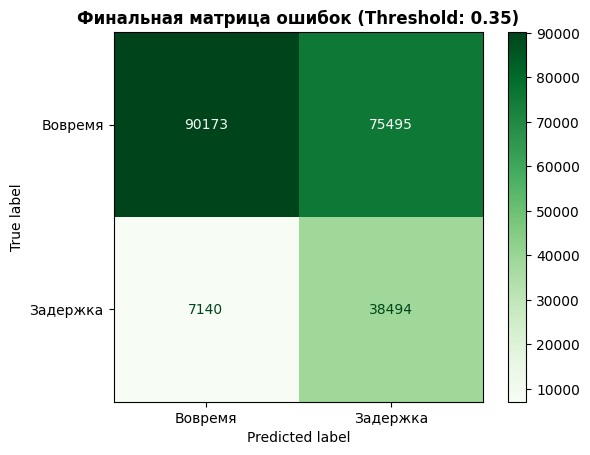

Поймано задержек: 38494 из 45634


In [43]:
from sklearn.metrics import ConfusionMatrixDisplay

# Устанавливаем новый выбранный порог
final_threshold = 0.35
y_final_pred = (y_probs >= final_threshold).astype(int)

# Строим красивую матрицу
plt.figure(figsize=(10, 8))
cm_final = confusion_matrix(y_test, y_final_pred)
disp = ConfusionMatrixDisplay(confusion_matrix=cm_final, display_labels=['Вовремя', 'Задержка'])
disp.plot(cmap='Greens', values_format='d')
plt.title(f'Финальная матрица ошибок (Threshold: {final_threshold})', weight='bold')
plt.savefig('notebooks/new_conf_matrix_035.jpg', dpi=300)

plt.show()
plt.close()

print(f"Поймано задержек: {cm_final[1,1]} из {cm_final[1,0] + cm_final[1,1]}")

In [44]:
# Так я недоволен метриками (Recall отличный, но Precision плох), попробуем проверить другой путь
# Посмотрим распределение задержек по разным порогам
delay_counts = pd.Series({
    "15+ мин (текущий)": (df['ARRIVAL_DELAY'] >= 15).sum(),
    "30+ мин":           (df['ARRIVAL_DELAY'] >= 30).sum(),
    "45+ мин":           (df['ARRIVAL_DELAY'] >= 45).sum(),
    "60+ мин":           (df['ARRIVAL_DELAY'] >= 60).sum()
})

delay_percents = (delay_counts / len(df)) * 100

print("Количество и доля задержек в данных:")
for label in delay_counts.index:
    print(f"{label:<18}: {delay_counts[label]:>8} рейс. ({delay_percents[label]:.2f}%)")

KeyError: 'ARRIVAL_DELAY'